# AP power

**Author**: laquitainesteeve@gmail.com

**Purpose**: Validation of AP power for dense probes

**Description**:
- highpass filtering with 300Hz cutoff 
- amplification gain 0.195 
- recording duration 2400 secs 

**Tested on**:
- Ubuntu 24.04.1 LTS (32 cores, 188 GB RAM, Intel(R) Core(TM) i9-14900K ＠3.2 GHz/5.8 GHz)

**Resources required**: 
- CPU
- 180 GB RAM 

## Setup

Prerequisites:

1. Setup "_envs/spikebias.yml_" virtual environment
2. Setup jupyter kernel _$python -m ipykernel install --user --name spikebias --display-name "spikebias"_
3. Download recordings: "_notebooks/0_download_recordings.ipynb_"
4. Pre-compute power spectral densities with: "_src/pipes/validation/psd/multiprocess.py_"

In [1]:
# import libs
%load_ext autoreload
%autoreload 2

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore")

import os
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import spikeinterface as si
import copy
import multiprocessing
import torch
import seaborn as sns
import pandas as pd
from scipy.stats import kruskal # stats
import scikit_posthocs as sp

# move to PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)

# import custom package
from src.nodes.validation import power

matplotlib.rcParams['agg.path.chunksize'] = 10000

# SETUP PARAMETERS
prm = dict()
prm["SFREQ_HV"] = 20000        # sampling frequency
prm["SFREQ_HS"] = 20000        # sampling frequency

# recording paths
RAW_PATH_hv1 =  "dataset/00_raw/recording_horvath_probe1"
RAW_PATH_hv2 =  "dataset/00_raw/recording_horvath_probe2"
RAW_PATH_hv3 =  "dataset/00_raw/recording_horvath_probe3"
RAW_PATH_hs1 = "dataset/00_raw/recording_dense_probe1"
RAW_PATH_hs2 = "dataset/00_raw/recording_dense_probe2"
RAW_PATH_hs3 = "dataset/00_raw/recording_dense_probe3"

# power spectral densities paths
PRE_PSD_PATH_HV1 = "dataset/01_intermediate/psds/psd_prep_horvath_probe1_cutoff_300.npy"
PRE_PSD_PATH_HV2 = "dataset/01_intermediate/psds/psd_prep_horvath_probe2_cutoff_300.npy"
PRE_PSD_PATH_HV3 = "dataset/01_intermediate/psds/psd_prep_horvath_probe3_cutoff_300.npy"
PRE_PSD_PATH_HS1 = "dataset/01_intermediate/psds/psd_prep_dense_probe1_cutoff_300.npy"
PRE_PSD_PATH_HS2 ="dataset/01_intermediate/psds/psd_prep_dense_probe2_cutoff_300.npy"
PRE_PSD_PATH_HS3 = "dataset/01_intermediate/psds/psd_prep_dense_probe3_cutoff_300.npy"

## pipeline parameters
SAVE_FIG = True
SAVE_TEMP_DATA = True
LOAD_TEMP_DATA = False

# setup intermediate dataset path
PLOT_DATA_PATH_DENSE = "dataset/02_figure_dataset/fig2t_data_APpower_dense.parquet"

# FIGURE SETTINGS
FIG_SIZE = (1.5, 1.5)

# experiment colors
cl = dict()
cl["COLOR_NV"] = [0.6, 0.6, 0.6]
cl["COLOR_NS"] = [0.9, 0.14, 0.15]
cl["COLOR_NB"] = [0.22, 0.5, 0.72] # blue
cl["COLOR_NE"] = [1, 0.49, 0] # orange
cl["COLOR_MEDIAN"] = (1, 0.76, 0)
cl["COLOR_HV"] = "k" # black
cl["COLOR_HS"] = np.array([26, 152, 80]) / 255 # green

# axes aesthetics
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically 0.5 - 1 pt
plt.rcParams["axes.linewidth"] = 0.5 # typically 0.5 - 1 pt
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
N_MAJOR_TICKS = 4
N_MINOR_TICKS = 12

savefig_cfg = {"transparent":True, "dpi":300, 'bbox_inches': "tight"}
legend_cfg = {"frameon": False, "handletextpad": 0.1}
tight_layout_cfg = {"pad": 0.5}
LG_FRAMEON = False              # no legend frame

In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Clear RAM

In [3]:
# (commented out: asks for the sudo password to clear the RAM cache, which blocks unattended runs)
# # clear ram
# import getpass; password = getpass.getpass("Enter your sudo password: ")
# !sync; echo {password} | sudo -S sh -c 'echo 1 > /proc/sys/vm/drop_caches'

## (1s)Load datasets

* select first 10 min for speed

In [4]:
# Load traces
RawHV1 = si.load_extractor(RAW_PATH_hv1)
RawHS1 = si.load_extractor(RAW_PATH_hs1)
RawHV2 = si.load_extractor(RAW_PATH_hv2)
RawHS2 = si.load_extractor(RAW_PATH_hs2)
RawHV3 = si.load_extractor(RAW_PATH_hv3)
RawHS3 = si.load_extractor(RAW_PATH_hs3)

# get good sites (in cortex)

# dense probe 1 (select L1, L2/3)
site_ly_hs1 = RawHS1.get_property("layers")
site_ly_hs1 = np.array(["L2_3" if x == "L2" or x == "L3" else x for x in site_ly_hs1])
sites_hs1 = np.where(np.isin(site_ly_hs1, ["L1", "L2_3"]))[0]
# dense probe 2 (select L4 and L5)
site_ly_hs2 = RawHS2.get_property("layers")
sites_hs2 = np.where(np.isin(site_ly_hs2, ["L4", "L5"]))[0]
# dense probe 3 (select L6)
site_ly_hs3 = RawHS3.get_property("layers")
site_ly_hs3 = np.array(["L2_3" if x == "L2" or x == "L3" else x for x in site_ly_hs3])
sites_hs3 = np.where(np.isin(site_ly_hs3, ["L6"]))[0]

# viv
# horvath probe 1
site_ly_hv1 = RawHV1.get_property("layers")
sites_hv1 = np.where(np.isin(site_ly_hv1, ["L1", "L2_3"]))[0]
# horvath probe 2
site_ly_hv2 = RawHV2.get_property("layers")
sites_hv2 = np.where(np.isin(site_ly_hv2, ["L4", "L5"]))[0]
# horvath probe 3
site_ly_hv3 = RawHV3.get_property("layers")
sites_hv3 = np.where(np.isin(site_ly_hv3, ["L6"]))[0]

# Load pre-computed PSDs (in cortex)
# preprocessed
psd_pre_hv1 = np.load(PRE_PSD_PATH_HV1, allow_pickle=True).item()
psd_pre_hv2 = np.load(PRE_PSD_PATH_HV2, allow_pickle=True).item()
psd_pre_hv3 = np.load(PRE_PSD_PATH_HV3, allow_pickle=True).item()
psd_pre_hs1 = np.load(PRE_PSD_PATH_HS1, allow_pickle=True).item()
psd_pre_hs2 = np.load(PRE_PSD_PATH_HS2, allow_pickle=True).item()
psd_pre_hs3 = np.load(PRE_PSD_PATH_HS3, allow_pickle=True).item()

# unit-test
assert psd_pre_hv1["freq"][1] == 1.0, "psd resolution should be 1Hz"
assert psd_pre_hv2["freq"][1] == 1.0, "psd resolution should be 1Hz"
assert psd_pre_hv3["freq"][1] == 1.0, "psd resolution should be 1Hz"
assert psd_pre_hs1["freq"][1] == 1.0, "psd resolution should be 1Hz"
assert psd_pre_hs2["freq"][1] == 1.0, "psd resolution should be 1Hz"
assert psd_pre_hs3["freq"][1] == 1.0, "psd resolution should be 1Hz"

### SAVE TEMP DATA

In [5]:
FIG_SIZE = (1.8, 1)

NORM = False

# calculate stats and plot data
d1 = power.get_psd_data_prepro_dense(
    "L1",
    psd_pre_hv1,
    psd_pre_hs1,
    site_ly_hv1[sites_hv1],
    site_ly_hs1[sites_hs1],
    norm=NORM,
)
d23 = power.get_psd_data_prepro_dense(
    "L2_3",
    psd_pre_hv1,
    psd_pre_hs1,
    site_ly_hv1[sites_hv1],
    site_ly_hs1[sites_hs1],
    norm=NORM,
)
d4 = power.get_psd_data_prepro_dense(
    "L4",
    psd_pre_hv2,
    psd_pre_hs2,
    site_ly_hv2[sites_hv2],
    site_ly_hs2[sites_hs2],
    norm=NORM,
)
d5 = power.get_psd_data_prepro_dense_layer_5(
    "L5",
    psd_pre_hv2,
    psd_pre_hs2,
    site_ly_hv2[sites_hv2],
    site_ly_hs2[sites_hs2],
    norm=NORM,
)
d6 = power.get_psd_data_prepro_dense(
    "L6",
    psd_pre_hv3,
    psd_pre_hs3,
    site_ly_hv3[sites_hv3],
    site_ly_hs3[sites_hs3],
    norm=NORM,
)

## (1s)AP power (dense probe)

2026-11-04 11:45:30,823 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - maxp pruned


2026-11-04 11:45:30,834 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - LTSH dropped


2026-11-04 11:45:30,835 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - cmap pruned


2026-11-04 11:45:30,837 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - kern pruned


2026-11-04 11:45:30,838 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - post pruned


2026-11-04 11:45:30,838 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - PCLT dropped


... (41 outputs left out)

2026-11-04 11:45:30,849 - fontTools.subset - __init__.py - _prune_post_subset - INFO - glyf pruned


2026-11-04 11:45:30,849 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GDEF pruned to empty; dropped


2026-11-04 11:45:30,849 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GSUB pruned


2026-11-04 11:45:30,851 - fontTools.subset - __init__.py - _prune_post_subset - INFO - name pruned


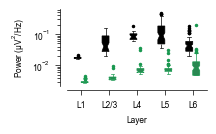

In [6]:
c_bot = 300  # spike with a period of 3 ms
c_up = 1000  # spike with a period of 0.5 ms

# Marques-Smith
df_hv1 = power.get_spiking_power(d1["psd_pre_hv_"], c_bot, c_up, "H", "L1")
df_hv23 = power.get_spiking_power(d23["psd_pre_hv_"], c_bot, c_up, "H", "L2_3")
df_hv4 = power.get_spiking_power(d4["psd_pre_hv_"], c_bot, c_up, "H", "L4")
df_hv5 = power.get_spiking_power(d5["psd_pre_hv_"], c_bot, c_up, "H", "L5")
df_hv6 = power.get_spiking_power(d6["psd_pre_hv_"], c_bot, c_up, "H", "L6")

# npx spontaneous
df_hs1 = power.get_spiking_power(d1["psd_pre_hs_"], c_bot, c_up, "DS", "L1")
df_hs23 = power.get_spiking_power(d23["psd_pre_hs_"], c_bot, c_up, "DS", "L2_3")
df_hs4 = power.get_spiking_power(d4["psd_pre_hs_"], c_bot, c_up, "DS", "L4")
df_hs5 = power.get_spiking_power(d5["psd_pre_hs_"], c_bot, c_up, "DS", "L5")
df_hs6 = power.get_spiking_power(d6["psd_pre_hs_"], c_bot, c_up, "DS", "L6")

# stack
plot_data = pd.concat(
    [
        df_hv1,
        df_hv23,
        df_hv4,
        df_hv5,
        df_hv6,
        df_hs1,
        df_hs23,
        df_hs4,
        df_hs5,
        df_hs6,
    ]
)

# standardize
plot_data["Layer"][plot_data["Layer"] == "L2_3"] = "L2/3"

# plot
fig, ax = plt.subplots(1, 1, figsize=FIG_SIZE)

ax = sns.boxplot(
    ax=ax,
    data=plot_data,
    x="Layer",
    y="power",
    hue="Experiment",
    notch=True,
    hue_order=["H", "DS"],
    palette=[cl["COLOR_HV"], cl["COLOR_HS"]],
    width=0.5,
    linewidth=0.5,
    flierprops={
        "marker": ".",
        "markersize": 3,
    },
)
ax.set_yscale("log")

# axes
ax.spines[["top", "right"]].set_visible(False)
ax.legend("", frameon=False)

# minor ticks
locmin = matplotlib.ticker.LogLocator(
    base=10.0,
    subs=np.arange(0, 1.1, 0.1),
    numticks=10,
)
ax.tick_params(which="both")
ax.yaxis.set_minor_locator(locmin)

# disconnect axes (R style)
ax.spines["bottom"].set_position(("axes", -0.05))
ax.yaxis.set_ticks_position("left")
ax.spines["left"].set_position(("axes", -0.05))

# ax.legend("", frameon=False)
ax.set_ylabel("Power ($\u03bcV^2$/Hz)")
ax.set_xlabel("Layer")
# ax.set_ylim([1.4, 3.7])


# customize the boxplot
p = 0
for box in ax.patches:
    if box.__class__.__name__ == "PathPatch":
        # a list item for each layer group
        if p in [0, 1, 2, 3, 4]:
            # Each box has 6 associated Line2D objects
            # (to make the whiskers, fliers, etc.)
            # Loop over them here, and use the same colour
            # as above
            # group 1 (NV)
            box.set_edgecolor(cl["COLOR_HV"])
            for k in range(6 * p, 6 * (p + 1)):
                ax.lines[k].set_color(cl["COLOR_HV"])  # box
                ax.lines[k].set_mfc(cl["COLOR_HV"])  # whisker
                ax.lines[k].set_mec(cl["COLOR_HV"])  # fliers
            p += 1
        elif p in [5, 6, 7, 8, 9]:
            # group 2 (DS)
            box.set_edgecolor(cl["COLOR_HS"])
            for k in range(6 * p, 6 * (p + 1)):
                ax.lines[k].set_color(cl["COLOR_HS"])
                ax.lines[k].set_mfc(cl["COLOR_HS"])
                ax.lines[k].set_mec(cl["COLOR_HS"])
            p += 1

# save
if SAVE_FIG:
    plt.savefig("figures/8_source_data/fig2t/fig2t.svg", **savefig_cfg)

## Create source data file

In [7]:
# display source data
display(plot_data)

# save to Excel
plot_data.to_excel(
    "figures/8_source_data/fig2t/fig2t.xlsx",
    index=False,
)

,power,Layer,Experiment
0,0.018242,L1,H
1,0.017485,L1,H
2,0.016676,L1,H
3,0.017664,L1,H
4,0.017915,L1,H
...,...,...,...
71,0.012356,L6,DS
72,0.004799,L6,DS
73,0.004797,L6,DS
74,0.004786,L6,DS


### SAVE TEMP data

In [8]:
# save plot and statistics data
if SAVE_TEMP_DATA:

    plot_data.to_parquet(PLOT_DATA_PATH_DENSE)
    print("Saved here:", PLOT_DATA_PATH_DENSE)

elif LOAD_TEMP_DATA:

    plot_data = pd.read_parquet(PLOT_DATA_PATH_DENSE)
    print("Loaded data")

Saved here: dataset/02_figure_dataset/fig2t_data_APpower_dense.parquet


### Hypothesis testing

In [9]:
def get_power(df, exp, layer):
    return df[(df.Experiment == exp) & (df.Layer == layer)]["power"].values


def get_kk(df, exp):
    """kruskall wallis test"""
    h, p = kruskal(
        get_power(df, exp, "L1"),
        get_power(df, exp, "L2/3"),
        get_power(df, exp, "L4"),
        get_power(df, exp, "L5"),
        get_power(df, exp, "L6"),
    )

    print(f"H={h}, p={p}")
    print(f"""N_L1 = {len(get_power(df, exp, "L1"))} sites""")
    print(f"""N_L23 = {len(get_power(df, exp, "L2/3"))} sites""")
    print(f"""N_L4 = {len(get_power(df, exp, "L4"))} sites""")
    print(f"""N_L5 = {len(get_power(df, exp, "L5"))} sites""")
    print(f"""N_L6 = {len(get_power(df, exp, "L6"))} sites""")


def get_posthoc_dunn_holm_sidak(df, exp):
    """posthoc test after kruskall wallis with Dunn and holm_sidak
    multiple comparison correction of p-values

    Args:
        df (_type_): _description_
        exp (_type_): _description_

    Returns:
        _type_: _description_
    """
    data = [
        get_power(df, exp, "L1"),
        get_power(df, exp, "L2/3"),
        get_power(df, exp, "L4"),
        get_power(df, exp, "L5"),
        get_power(df, exp, "L6"),
    ]
    # holm sidak method has more power than Bonferroni which is more conservative
    # Non-significance can indicate subtle differences, power issues, samll sample size,
    # or the balancing be due to how the Holm-Sidak correction controls Type I errors
    # while retaining power.
    # we can still look at the p-values to identify trends.
    df = sp.posthoc_dunn(data, p_adjust="holm-sidak")
    df.columns = ["L1", "L2/3", "L4", "L5", "L6"]
    df.index = ["L1", "L2/3", "L4", "L5", "L6"]
    return df


def ci95(data):
    return 1.96 * np.nanstd(data) / np.sqrt(np.sum(~np.isnan(data)))


def get_medians_and_ci95(plot_data, exp, feature: str):
    layers = ["L1", "L2/3", "L4", "L5", "L6"]
    stats = ""
    record = []
    for layer in layers:
        feature_data = plot_data[
            (plot_data.Experiment == exp) & (plot_data.Layer == layer)
        ][feature]
        stats += f"{np.round(feature_data.median()*10000)/10000} $\pm$ {np.round(ci95(feature_data),6)}, "
        record.append(np.round(feature_data.median() * 10000) / 10000)
    print(stats)
    return record

### Power changes across layers?

DENSE

In [10]:
# standardize layer
print("\n--------------------H--------------------\n")
plot_data.Layer[plot_data.Layer == "L2_3"] = "L2/3"
get_kk(plot_data, "H")
display(get_posthoc_dunn_holm_sidak(plot_data, "H"))
m_h = get_medians_and_ci95(plot_data, "H", "power")

print("\n--------------------DS--------------------\n")

get_kk(plot_data, "DS")
display(get_posthoc_dunn_holm_sidak(plot_data, "DS"))
m_ds = get_medians_and_ci95(plot_data, "DS", "power")


--------------------H--------------------

H=135.5884214857614, p=2.4825629054482386e-28
N_L1 = 36 sites
N_L23 = 60 sites
N_L4 = 20 sites
N_L5 = 88 sites
N_L6 = 68 sites


,L1,L2/3,L4,L5,L6
L1,1.000000e+00,4.564846e-10,1.511378e-14,3.435914e-27,2.394184e-09
L2/3,4.564846e-10,1.000000e+00,3.434597e-03,9.650322e-06,8.579679e-01
L4,1.511378e-14,3.434597e-03,1.000000e+00,8.634126e-01,1.077346e-03
L5,3.435914e-27,9.650322e-06,8.634126e-01,1.000000e+00,2.617829e-07
L6,2.394184e-09,8.579679e-01,1.077346e-03,2.617829e-07,1.000000e+00


0.0175 $\pm$ 0.000362, 0.0405 $\pm$ 0.009621, 0.0821 $\pm$ 0.012109, 0.088 $\pm$ 0.02271, 0.0419 $\pm$ 0.008339, 

--------------------DS--------------------



H=193.47341268221794, p=9.502545069251471e-41


N_L1 = 37 sites


N_L23 = 64 sites
N_L4 = 32 sites
N_L5 = 88 sites
N_L6 = 76 sites


,L1,L2/3,L4,L5,L6
L1,1.000000e+00,4.113969e-02,1.284533e-13,4.719111e-24,1.429281e-23
L2/3,4.113969e-02,1.000000e+00,6.078477e-09,6.506299e-19,2.263048e-18
L4,1.284533e-13,6.078477e-09,1.000000e+00,7.025520e-01,7.025520e-01
L5,4.719111e-24,6.506299e-19,7.025520e-01,1.000000e+00,8.814612e-01
L6,1.429281e-23,2.263048e-18,7.025520e-01,8.814612e-01,1.000000e+00


0.0029 $\pm$ 0.000143, 0.0039 $\pm$ 0.000243, 0.0064 $\pm$ 0.002308, 0.0069 $\pm$ 0.000709, 0.0083 $\pm$ 0.004811, 


## Are models and in vivo power the same?

In [11]:
from scipy.stats import kruskal
import scikit_posthocs as sp


def count_sites(df, exp, layer):
    return len(df[(df["Experiment"] == exp) & (df["Layer"] == layer)])


def get_power(df, exp, layer):
    return df[(df["Experiment"] == exp) & (df["Layer"] == layer)]["power"].values


def get_kk_compare_exps(df, layer):
    """kruskall wallis test"""
    h, p = kruskal(
        get_power(df, "H", layer),
        get_power(df, "DS", layer),
    )
    print(f"H={h}, p={p}")
    print(f"""N_H = {count_sites(df, "H", layer)} sites""")
    print(f"""N_DS = {count_sites(df, "DS", layer)} sites""")


def get_posthoc_dunn_holm_sidak_compare_exps(plot_data, layer):
    """posthoc test after kruskall wallis with Dunn and holm_sidak
    multiple comparison correction of p-values

    Args:
        plot_data (_type_): _description_
        exp (_type_): _description_

    Returns:
        _type_: _description_
    """
    data = [
        get_power(plot_data, "H", layer),
        get_power(plot_data, "DS", layer),
    ]
    # holm sidak method has more power than Bonferroni which is more conservative
    # Non-significance can indicate subtle differences, power issues, samll sample size,
    # or the balancing be due to how the Holm-Sidak correction controls Type I errors
    # while retaining power.
    # we can still look at the p-values to identify trends.
    df = sp.posthoc_dunn(data, p_adjust="holm-sidak")
    df.columns = ["H", "DS"]
    df.index = ["H", "DS"]
    return df


def get_posthoc_dunn_holm_sidak_compare_exps_l5(plot_data, layer):
    """posthoc test after kruskall wallis with Dunn and holm_sidak
    multiple comparison correction of p-values

    Args:
        plot_data (_type_): _description_
        exp (_type_): _description_

    Returns:
        _type_: _description_
    """
    data = [
        get_power(plot_data, "H", layer),
        get_power(plot_data, "DS", layer),
    ]
    # holm sidak method has more power than Bonferroni which is more conservative
    # Non-significance can indicate subtle differences, power issues, samll sample size,
    # or the balancing be due to how the Holm-Sidak correction controls Type I errors
    # while retaining power.
    # we can still look at the p-values to identify trends.
    df = sp.posthoc_dunn(data, p_adjust="holm-sidak")
    df.columns = ["H", "DS"]
    df.index = ["H", "DS"]
    return df

In [12]:
print("------LAYER 1:------\n")

# kruskall-wallis
# perform Dunn's posthoc test using a holm-sidak correction for the p-values
# to identify the layer amplitudes that significantly deviate from others
get_kk_compare_exps(plot_data, "L1")
display(get_posthoc_dunn_holm_sidak_compare_exps(plot_data, "L1"))


print("\n------LAYER 2/3:------\n")

get_kk_compare_exps(plot_data, "L2/3")
display(get_posthoc_dunn_holm_sidak_compare_exps(plot_data, "L2/3"))

print("\n------LAYER 4:------\n")

get_kk_compare_exps(plot_data, "L4")
display(get_posthoc_dunn_holm_sidak_compare_exps(plot_data, "L4"))

print("\n------LAYER 5:------\n")

get_kk_compare_exps(plot_data, "L5")
display(get_posthoc_dunn_holm_sidak_compare_exps_l5(plot_data, "L5"))

print("\n------LAYER 6:------\n")

get_kk_compare_exps(plot_data, "L6")
display(get_posthoc_dunn_holm_sidak_compare_exps(plot_data, "L6"))

------LAYER 1:------

H=54.0, p=2.0048960802803017e-13
N_H = 36 sites
N_DS = 37 sites


,H,DS
H,1.000000e+00,2.004896e-13
DS,2.004896e-13,1.000000e+00



------LAYER 2/3:------

H=92.15999999999997, p=7.994442411452592e-22
N_H = 60 sites
N_DS = 64 sites


,H,DS
H,1.000000e+00,7.994442e-22
DS,7.994442e-22,1.000000e+00



------LAYER 4:------

H=36.226415094339615, p=1.7567319179177604e-09
N_H = 20 sites
N_DS = 32 sites


,H,DS
H,1.000000e+00,1.756732e-09
DS,1.756732e-09,1.000000e+00



------LAYER 5:------

H=131.25423728813564, p=2.1784112745805386e-30
N_H = 88 sites
N_DS = 88 sites


,H,DS
H,1.000000e+00,2.178411e-30
DS,2.178411e-30,1.000000e+00



------LAYER 6:------

H=94.09270844453931, p=3.0108636804609358e-22
N_H = 68 sites
N_DS = 76 sites


,H,DS
H,1.000000e+00,3.010864e-22
DS,3.010864e-22,1.000000e+00


# Summary statistics

In [13]:
def pc(x1, x2):
    return (x1 - x2) / x1 * 100

In [14]:
# calculate median powers
m_h = get_medians_and_ci95(plot_data, "H", "power")
m_ds = get_medians_and_ci95(plot_data, "DS", "power")

pc_change = -np.median((np.array(m_h) - np.array(m_ds)) / np.array(m_h))
print("\nModels median power are on average ", pc_change, "% than Horvath data")

0.0175 $\pm$ 0.000362, 0.0405 $\pm$ 0.009621, 0.0821 $\pm$ 0.012109, 0.088 $\pm$ 0.02271, 0.0419 $\pm$ 0.008339, 
0.0029 $\pm$ 0.000143, 0.0039 $\pm$ 0.000243, 0.0064 $\pm$ 0.002308, 0.0069 $\pm$ 0.000709, 0.0083 $\pm$ 0.004811, 

Models median power are on average  -0.9037037037037037 % than Horvath data


## Panel t with the statistics and the median ± 95% CI labels of the paper

Drawn from the source data (`fig2t.xlsx`): Kruskal–Wallis test between Horvath (H) and the dense-probe model (DS) in each layer (ns p ≥ 0.05, * p < 0.05, ** p < 0.01, *** p < 0.001); labels: median ± 95% CI with one significant digit. Overwrites `fig2t.svg` and `fig2t.pdf`.

2026-11-04 11:45:31,336 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - maxp pruned


2026-11-04 11:45:31,337 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - LTSH dropped


2026-11-04 11:45:31,337 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - cmap pruned


2026-11-04 11:45:31,339 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - kern pruned


2026-11-04 11:45:31,339 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - post pruned


2026-11-04 11:45:31,339 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - PCLT dropped


... (93 outputs left out)

2026-11-04 11:45:31,367 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GDEF pruned to empty; dropped


2026-11-04 11:45:31,367 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GSUB pruned


2026-11-04 11:45:31,368 - fontTools.subset - __init__.py - _prune_post_subset - INFO - name pruned


H ['0.02 ± 4e-4', '0.04 ± 0.01', '0.08 ± 0.01', '0.09 ± 0.02', '0.04 ± 8e-3']
DS ['3e-3 ± 1e-4', '4e-3 ± 2e-4', '6e-3 ± 2e-3', '7e-3 ± 7e-4', '8e-3 ± 5e-3']


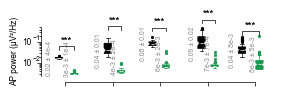

In [15]:
import pandas as pd
from src.nodes.validation import ap_power_plots

df_t = pd.read_excel("figures/8_source_data/fig2t/fig2t.xlsx")
fig = ap_power_plots.plot_ap_power_dense(df_t)
fig.savefig("figures/8_source_data/fig2t/fig2t.svg", transparent=True, dpi=300)     # also saves the .pdf (figure_style)

# labels and tests, for the record
for exp in ["H", "DS"]:
    print(exp, [ap_power_plots.label(df_t[(df_t.Experiment == exp) & (df_t.Layer == l)].power) for l in ap_power_plots.LAYERS])